# Dairy Calf Feed Intake, Growth and Feed Efficiency Analysis

## Project Overview

This project uses published dairy-calf research data to investigate feed consumption, body-weight development, and growth performance.

## Research Question

How do feed intake and growth change during the preweaning period in dairy calves, and what can the available data tell us about their relationship?

## Data Source

Public research data hosted by Dryad, associated with a published dairy-calf feeding study.

## Tools

Python, pandas, Matplotlib, SciPy, Google Colab, and GitHub.

**Purpose:** Check that all four original research files are present in the Colab working directory before beginning data inspection.

In [7]:
# Step 3: Verify the four research files

import os

required_files = [
    "JDS.2021-21439_Grain_intake_data.csv",
    "JDS.2021-21439_Hay_intake_data.csv",
    "JDS.2021-21439_TMR_intake_data.csv",
    "JDS.2021-21439_Weekly_calf_weights_and_ADG.xlsx"
]

for filename in required_files:
    if os.path.exists(filename):
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")

FOUND: JDS.2021-21439_Grain_intake_data.csv
FOUND: JDS.2021-21439_Hay_intake_data.csv
FOUND: JDS.2021-21439_TMR_intake_data.csv
FOUND: JDS.2021-21439_Weekly_calf_weights_and_ADG.xlsx


**Purpose:** Load the original dairy-calf feed-intake and body-weight files into pandas DataFrames. The original files remain unchanged; the data are only loaded into memory for analysis.

In [8]:
# Step 4: Load the four research datasets

import pandas as pd

grain = pd.read_csv("JDS.2021-21439_Grain_intake_data.csv")
hay = pd.read_csv("JDS.2021-21439_Hay_intake_data.csv")
tmr = pd.read_csv("JDS.2021-21439_TMR_intake_data.csv")
weights = pd.read_excel(
    "JDS.2021-21439_Weekly_calf_weights_and_ADG.xlsx"
)

print("All four research datasets loaded successfully.")


All four research datasets loaded successfully.


**Purpose:** Report the number of rows and columns in each loaded dataset. Rows represent recorded observations, while columns represent variables such as calf ID, age, treatment, feed intake, or body weight.

In [9]:
# Step 5: Check dataset dimensions

datasets = {
    "Grain intake": grain,
    "Hay intake": hay,
    "TMR intake": tmr,
    "Weekly calf weights": weights
}

for name, data in datasets.items():
    print(f"{name}: {data.shape[0]} rows, {data.shape[1]} columns")

Grain intake: 1321 rows, 6 columns
Hay intake: 539 rows, 6 columns
TMR intake: 241 rows, 6 columns
Weekly calf weights: 206 rows, 6 columns


**Purpose:** Display the column names in each dataset. This identifies the available variables and helps determine which measurements can be used in later analyses.

In [10]:
# Step 6: Display column names

for name, data in datasets.items():
    print(f"\n{name}")
    print(data.columns.tolist())


Grain intake
['Calf', 'Age_days', 'Date', 'Week', 'Treatment', 'Grain_consumed_dried_g']

Hay intake
['Calf', 'Age_days', 'Date', 'Week', 'Treatment', 'Hay_consumed_dried_g']

TMR intake
['Calf', 'Age_days', 'Date', 'Week', 'Treatment', 'TMR_consumed_dried_g']

Weekly calf weights
['Date', 'Calf', 'Age_days', 'Week', 'Treatment', 'Weight_kg']


**Purpose:** Inspect the data types of each column to identify variables that may require conversion before statistical analysis or visualization.

In [11]:
# Step 7: Inspect column data types

for name, data in datasets.items():
    print(f"\n{name}")
    print(data.dtypes)


Grain intake
Calf                        int64
Age_days                    int64
Date                       object
Week                        int64
Treatment                  object
Grain_consumed_dried_g    float64
dtype: object

Hay intake
Calf                      int64
Age_days                  int64
Date                     object
Week                      int64
Treatment                object
Hay_consumed_dried_g    float64
dtype: object

TMR intake
Calf                      int64
Age_days                  int64
Date                     object
Week                      int64
Treatment                object
TMR_consumed_dried_g    float64
dtype: object

Weekly calf weights
Date         datetime64[ns]
Calf                  int64
Age_days              int64
Week                  int64
Treatment            object
Weight_kg           float64
dtype: object


**Purpose:** Count missing values in every column of the four research datasets. This check identifies incomplete observations before analysis and helps us decide which variables need further investigation.

In [12]:
# Step 8: Count missing values

for name, data in datasets.items():
    print(f"\n{name}")
    print(data.isna().sum())


Grain intake
Calf                        0
Age_days                    0
Date                        0
Week                        0
Treatment                   0
Grain_consumed_dried_g    110
dtype: int64

Hay intake
Calf                      0
Age_days                  0
Date                      0
Week                      0
Treatment                 0
Hay_consumed_dried_g    124
dtype: int64

TMR intake
Calf                     0
Age_days                 0
Date                     0
Week                     0
Treatment                0
TMR_consumed_dried_g    49
dtype: int64

Weekly calf weights
Date         0
Calf         0
Age_days     0
Week         0
Treatment    0
Weight_kg    0
dtype: int64


**Purpose:** Identify repeated calf-date combinations in each dataset. This validation step helps determine whether records need investigation before calculating summaries or combining measurements across files.

In [13]:
# Step 9: Check duplicate calf-date records

for name, data in datasets.items():
    duplicate_count = data.duplicated(
        subset=["Calf", "Date"]
    ).sum()

    print(f"{name}: {duplicate_count} duplicate calf-date rows")

Grain intake: 0 duplicate calf-date rows
Hay intake: 0 duplicate calf-date rows
TMR intake: 0 duplicate calf-date rows
Weekly calf weights: 0 duplicate calf-date rows


**Purpose:** Count unique calves and recorded rows by treatment group in each dataset. This helps verify the group labels and understand how observations are distributed between calves assigned to hay access and the control group.

In [14]:
# Step 10: Inspect treatment groups and calf counts

for name, data in datasets.items():
    print(f"\n{name}")
    print("Treatment labels:", sorted(data["Treatment"].dropna().unique()))

    summary = data.groupby("Treatment").agg(
        rows=("Calf", "size"),
        unique_calves=("Calf", "nunique")
    )

    print(summary)


Grain intake
Treatment labels: ['Control', 'Hay']
           rows  unique_calves
Treatment                     
Control     661             11
Hay         660             11

Hay intake
Treatment labels: ['Hay']
           rows  unique_calves
Treatment                     
Hay         539             11

TMR intake
Treatment labels: ['Control', 'Hay']
           rows  unique_calves
Treatment                     
Control     121             11
Hay         120             11

Weekly calf weights
Treatment labels: ['Control', 'Hay']
           rows  unique_calves
Treatment                     
Control     103             11
Hay         103             11


**Purpose:** Summarize the minimum and maximum recorded ages and study weeks for each dataset. These ranges help identify the observation periods available for feed-intake and growth analyses.

In [15]:
# Step 11: Check age and study-week ranges

for name, data in datasets.items():
    print(f"\n{name}")
    print(
        "Age range (days):",
        data["Age_days"].min(),
        "to",
        data["Age_days"].max()
    )
    print(
        "Study week range:",
        data["Week"].min(),
        "to",
        data["Week"].max()
    )


Grain intake
Age range (days): 1 to 61
Study week range: 0 to 8

Hay intake
Age range (days): 1 to 50
Study week range: 0 to 7

TMR intake
Age range (days): 49 to 61
Study week range: 7 to 8

Weekly calf weights
Age range (days): 0 to 61
Study week range: 0 to 8


**Purpose:** Display the first ten weekly body-weight observations, including calf ID, age, treatment group, and weight in kilograms. This provides a closer look at the growth dataset before summarizing or visualizing it.

In [16]:
# Step 12: Preview weekly calf weights

display(weights.head(10))

,Date,Calf,Age_days,Week,Treatment,Weight_kg
0,2018-07-20,2933,0,0,Hay,40.36
1,2018-07-22,2934,0,0,Control,41.27
2,2018-07-22,2935,0,0,Hay,37.64
3,2018-07-22,2936,0,0,Control,49.89
4,2018-07-22,2937,0,0,Hay,43.09
5,2018-07-22,2938,0,0,Control,37.19
6,2018-07-22,2939,0,0,Hay,40.82
7,2018-07-23,2933,3,0,Hay,35.27
8,2018-07-27,2940,0,0,Control,36.74
9,2018-07-29,2941,0,0,Hay,34.92


Step 13 — Summarize body weight by study week

In [17]:
# Step 13: Summarize body weight by treatment and week

weight_summary = (
    weights.groupby(["Treatment", "Week"])["Weight_kg"]
    .agg(
        records="count",
        mean_weight="mean",
        sd_weight="std",
        minimum="min",
        maximum="max"
    )
    .round(2)
    .reset_index()
)

display(weight_summary)

,Treatment,Week,records,mean_weight,sd_weight,minimum,maximum
0,Control,0,17,37.28,4.42,32.20,49.89
1,Control,1,11,37.96,1.73,34.24,39.91
2,Control,2,11,40.61,3.08,37.48,48.46
3,Control,3,11,46.25,3.97,39.91,53.45
4,Control,4,11,51.80,2.83,46.90,57.04
5,Control,5,12,61.30,4.49,53.45,69.10
6,Control,6,11,67.49,5.18,58.92,73.54
7,Control,7,11,72.44,5.12,64.87,78.20
8,Control,8,8,81.66,5.78,71.29,88.15
9,Hay,0,18,37.85,4.96,31.75,48.98


Step 14 — Plot average calf weight over time

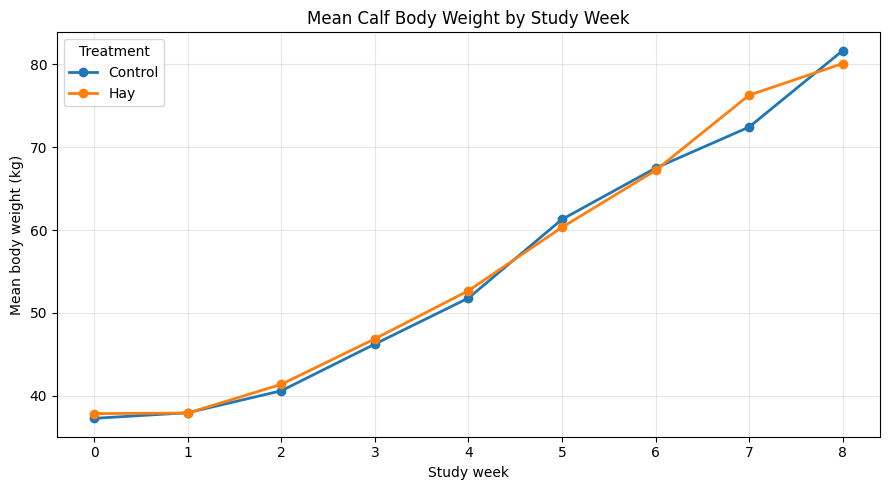

In [18]:
# Step 14: Plot mean body weight by study week

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for treatment in ["Control", "Hay"]:
    group_data = weight_summary[
        weight_summary["Treatment"] == treatment
    ].sort_values("Week")

    plt.plot(
        group_data["Week"],
        group_data["mean_weight"],
        marker="o",
        linewidth=2,
        label=treatment
    )

plt.title("Mean Calf Body Weight by Study Week")
plt.xlabel("Study week")
plt.ylabel("Mean body weight (kg)")
plt.xticks(range(0, 9))
plt.legend(title="Treatment")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Purpose:** Compare mean body weight between the Hay and Control groups at each study week by calculating the difference in group means. These are descriptive comparisons and do not establish statistical significance or causation.

In [19]:
# Step 15: Calculate weekly differences in mean body weight

weight_comparison = weight_summary.pivot(
    index="Week",
    columns="Treatment",
    values="mean_weight"
)

weight_comparison["Hay_minus_Control_kg"] = (
    weight_comparison["Hay"] - weight_comparison["Control"]
)

display(weight_comparison.round(2))

Treatment,Control,Hay,Hay_minus_Control_kg
Week,,,
0,37.28,37.85,0.57
1,37.96,37.92,-0.04
2,40.61,41.39,0.78
3,46.25,46.88,0.63
4,51.80,52.69,0.89
5,61.30,60.34,-0.96
6,67.49,67.21,-0.28
7,72.44,76.29,3.85
8,81.66,80.11,-1.55


**Purpose:** Calculate each calf's first recorded weight, last recorded weight, age at each measurement, and total observed weight change. The observation periods may differ between calves, so weight change will not automatically be interpreted as average daily gain.

In [20]:
# Step 16: Calculate observed weight change for each calf

weights_sorted = weights.sort_values(["Calf", "Age_days", "Date"])

first_weights = (
    weights_sorted.groupby("Calf", as_index=False)
    .first()[["Calf", "Treatment", "Age_days", "Weight_kg"]]
    .rename(columns={
        "Age_days": "First_age_days",
        "Weight_kg": "First_weight_kg"
    })
)

last_weights = (
    weights_sorted.groupby("Calf", as_index=False)
    .last()[["Calf", "Age_days", "Weight_kg"]]
    .rename(columns={
        "Age_days": "Last_age_days",
        "Weight_kg": "Last_weight_kg"
    })
)

calf_growth = first_weights.merge(last_weights, on="Calf")

calf_growth["Observed_weight_change_kg"] = (
    calf_growth["Last_weight_kg"] - calf_growth["First_weight_kg"]
)

calf_growth["Observation_days"] = (
    calf_growth["Last_age_days"] - calf_growth["First_age_days"]
)

display(calf_growth.round(2))

,Calf,Treatment,First_age_days,First_weight_kg,Last_age_days,Last_weight_kg,Observed_weight_change_kg,Observation_days
0,2933,Hay,0,40.36,59,83.07,42.71,59
1,2934,Control,0,41.27,57,78.20,36.93,57
2,2935,Hay,0,37.64,57,71.29,33.65,57
3,2936,Control,0,49.89,57,88.15,38.26,57
4,2937,Hay,0,43.09,57,90.77,47.68,57
5,2938,Control,0,37.19,57,78.20,41.01,57
6,2939,Hay,0,40.82,57,83.07,42.25,57
7,2940,Control,0,36.74,59,71.29,34.55,59
8,2941,Hay,0,34.92,57,71.29,36.37,57
9,2942,Control,0,40.82,61,85.58,44.76,61


**Purpose:** Calculate descriptive statistics for each treatment group's observed body-weight change and observation duration. This provides a preliminary group comparison without assuming all calves were observed for the same number of days.

In [21]:
# Step 17: Summarize observed calf growth by treatment

growth_summary = (
    calf_growth.groupby("Treatment")
    .agg(
        calves=("Calf", "nunique"),
        mean_weight_change_kg=("Observed_weight_change_kg", "mean"),
        sd_weight_change_kg=("Observed_weight_change_kg", "std"),
        mean_observation_days=("Observation_days", "mean"),
        min_observation_days=("Observation_days", "min"),
        max_observation_days=("Observation_days", "max")
    )
    .round(2)
)

display(growth_summary)

,calves,mean_weight_change_kg,sd_weight_change_kg,mean_observation_days,min_observation_days,max_observation_days
Treatment,,,,,,
Control,11,41.4,5.48,57.00,53,61
Hay,11,41.8,4.67,56.36,53,59


**Purpose:** Calculate observed average daily gain (ADG) for each calf by dividing its observed body-weight change by the number of days between its first and last weight measurements. This is an endpoint-based estimate, not necessarily the study's official ADG measure.

In [22]:
# Step 18: Calculate observed average daily gain

calf_growth["Observed_ADG_kg_per_day"] = (
    calf_growth["Observed_weight_change_kg"]
    / calf_growth["Observation_days"]
)

display(
    calf_growth[
        ["Calf", "Treatment", "Observation_days",
         "Observed_weight_change_kg", "Observed_ADG_kg_per_day"]
    ].round(3)
)

,Calf,Treatment,Observation_days,Observed_weight_change_kg,Observed_ADG_kg_per_day
0,2933,Hay,59,42.71,0.724
1,2934,Control,57,36.93,0.648
2,2935,Hay,57,33.65,0.590
3,2936,Control,57,38.26,0.671
4,2937,Hay,57,47.68,0.836
5,2938,Control,57,41.01,0.719
6,2939,Hay,57,42.25,0.741
7,2940,Control,59,34.55,0.586
8,2941,Hay,57,36.37,0.638
9,2942,Control,61,44.76,0.734


**Purpose:** Summarize each treatment group's observed average daily gain (ADG), including the number of calves, mean, standard deviation, minimum, and maximum. ADG is calculated from each calf's first and last recorded weights, so it may differ from the study's officially reported ADG.

In [23]:
# Step 19: Summarize observed ADG by treatment

adg_summary = (
    calf_growth.groupby("Treatment")["Observed_ADG_kg_per_day"]
    .agg(
        calves="count",
        mean_ADG="mean",
        sd_ADG="std",
        minimum="min",
        maximum="max"
    )
    .round(3)
    .reset_index()
)

display(adg_summary)

,Treatment,calves,mean_ADG,sd_ADG,minimum,maximum
0,Control,11,0.727,0.096,0.586,0.926
1,Hay,11,0.743,0.095,0.590,0.887


**Purpose:** Visualize the distribution of observed average daily gain (ADG) for individual calves in the Control and Hay groups. This graph helps compare variation between calves and identify potentially unusual observations without removing any data.

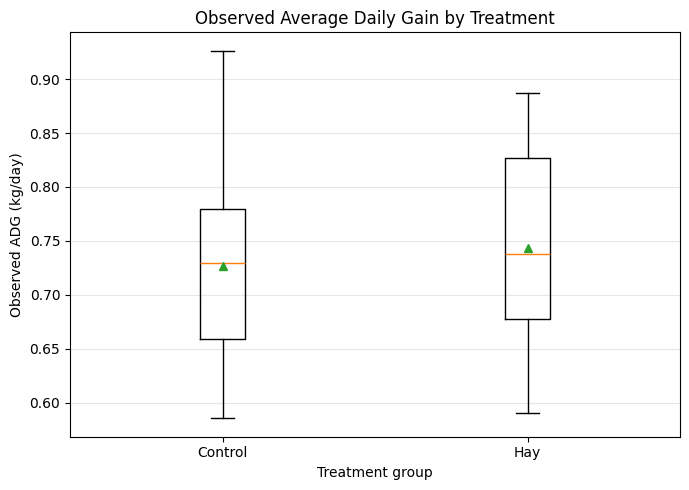

In [24]:
# Step 20: Plot individual calf ADG by treatment

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

adg_control = calf_growth.loc[
    calf_growth["Treatment"] == "Control",
    "Observed_ADG_kg_per_day"
]

adg_hay = calf_growth.loc[
    calf_growth["Treatment"] == "Hay",
    "Observed_ADG_kg_per_day"
]

plt.boxplot(
    [adg_control, adg_hay],
    tick_labels=["Control", "Hay"],
    showmeans=True
)

plt.title("Observed Average Daily Gain by Treatment")
plt.xlabel("Treatment group")
plt.ylabel("Observed ADG (kg/day)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Step 21: Inspect the original workbook's sheet names

import pandas as pd

workbook = pd.ExcelFile(
    "JDS.2021-21439_Weekly_calf_weights_and_ADG.xlsx"
)

print(workbook.sheet_names)

['Weekly calf weights', 'Weekly ADG']


**Purpose:** Inspect the original Weekly ADG sheet to identify the available variables and understand how the researchers recorded average daily gain. We will preserve the original values and compare them with our calculated measure only after checking the data structure.

In [26]:
# Step 22: Load and inspect the official ADG sheet

official_adg = pd.read_excel(
    "JDS.2021-21439_Weekly_calf_weights_and_ADG.xlsx",
    sheet_name="Weekly ADG"
)

print("Shape:", official_adg.shape)
print("Columns:", official_adg.columns.tolist())

display(official_adg.head(10))

Shape: (184, 6)
Columns: ['Date', 'Calf', 'Age_days', 'Week', 'Treatment', 'ADG_kg/d']


,Date,Calf,Age_days,Week,Treatment,ADG_kg/d
0,2018-07-23,2933,3,0,Hay,-1.696667
1,2018-07-30,2933,10,1,Hay,0.847143
2,2018-07-30,2934,8,1,Control,-0.170000
3,2018-07-30,2935,8,1,Hay,-0.161250
4,2018-07-30,2936,8,1,Control,-1.247500
5,2018-07-30,2937,8,1,Hay,-0.701250
6,2018-07-30,2938,8,1,Control,-0.105000
7,2018-07-30,2939,8,1,Hay,-0.417500
8,2018-07-30,2940,3,0,Control,-0.490000
9,2018-07-30,2941,1,0,Hay,-2.570000


**Purpose:** Check missing values in the official ADG sheet and summarize its record counts, unique calves, and ADG observations by treatment. This validates the data before any statistical comparison.

In [27]:
# Step 23: Validate official ADG data

print("Missing values by column:")
print(official_adg.isna().sum())

print("\nADG summary by treatment:")

adg_data_summary = official_adg.groupby("Treatment").agg(
    records=("ADG_kg/d", "size"),
    unique_calves=("Calf", "nunique"),
    valid_ADG=("ADG_kg/d", "count"),
    mean_ADG=("ADG_kg/d", "mean"),
    sd_ADG=("ADG_kg/d", "std")
).round(3)

display(adg_data_summary)

Missing values by column:
Date         0
Calf         0
Age_days     0
Week         0
Treatment    0
ADG_kg/d     0
dtype: int64

ADG summary by treatment:


,records,unique_calves,valid_ADG,mean_ADG,sd_ADG
Treatment,,,,,
Control,92,11,92,0.692,0.723
Hay,92,11,92,0.664,0.818


**Purpose:** Count official ADG records for each calf and identify the age range covered by those records. This helps assess the repeated-measures structure before comparing treatment groups.


In [28]:
# Step 24: Count official ADG records per calf

adg_records_per_calf = (
    official_adg.groupby(["Treatment", "Calf"])
    .agg(
        adg_records=("ADG_kg/d", "count"),
        first_age_days=("Age_days", "min"),
        last_age_days=("Age_days", "max")
    )
    .reset_index()
    .sort_values(["Treatment", "Calf"])
)

display(adg_records_per_calf)

,Treatment,Calf,adg_records,first_age_days,last_age_days
0,Control,2934,8,8,57
1,Control,2936,8,8,57
2,Control,2938,8,8,57
3,Control,2940,9,3,59
4,Control,2942,9,4,61
5,Control,2944,8,5,55
6,Control,2948,8,5,53
7,Control,2949,9,4,60
8,Control,2950,8,7,56
9,Control,2952,9,2,57


Step 25 — Calculate mean official ADG for each calf

In [29]:
# Step 25: Calculate mean official ADG for each calf

calf_official_adg = (
    official_adg.groupby(["Treatment", "Calf"])
    .agg(
        mean_official_ADG_kg_per_day=("ADG_kg/d", "mean"),
        adg_records=("ADG_kg/d", "count")
    )
    .reset_index()
)

display(calf_official_adg)

official_adg_by_treatment = (
    calf_official_adg.groupby("Treatment")
    ["mean_official_ADG_kg_per_day"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)

display(official_adg_by_treatment)

,Treatment,Calf,mean_official_ADG_kg_per_day,adg_records
0,Control,2934,0.662500,8
1,Control,2936,0.705491,8
2,Control,2938,0.734196,8
3,Control,2940,0.517302,9
4,Control,2942,0.642619,9
5,Control,2944,0.695054,8
6,Control,2948,0.765089,8
7,Control,2949,0.709530,9
8,Control,2950,0.900335,8
9,Control,2952,0.654478,9


,count,mean,std,min,max
Treatment,,,,,
Control,11,0.695,0.093,0.517,0.900
Hay,11,0.671,0.172,0.333,0.866


Step 26 — Visualize mean official ADG by treatment

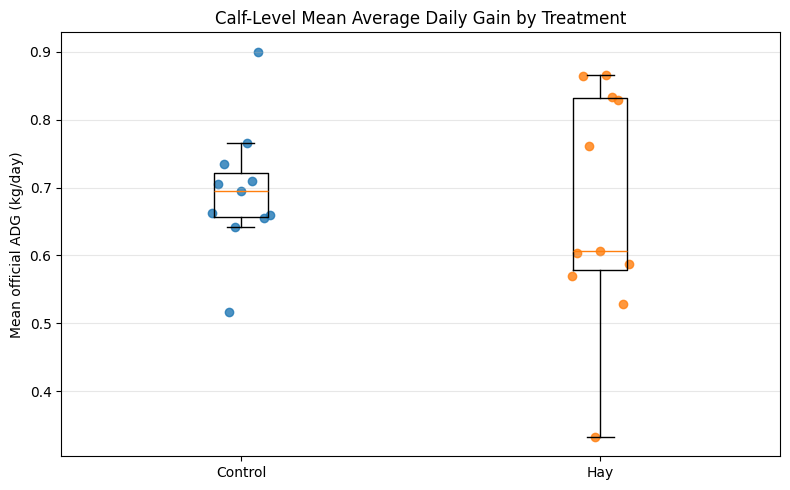

In [30]:
# Step 26: Compare calf-level mean official ADG

import matplotlib.pyplot as plt
import numpy as np

control_adg = calf_official_adg.loc[
    calf_official_adg["Treatment"] == "Control",
    "mean_official_ADG_kg_per_day"
].values

hay_adg = calf_official_adg.loc[
    calf_official_adg["Treatment"] == "Hay",
    "mean_official_ADG_kg_per_day"
].values

plt.figure(figsize=(8, 5))

plt.boxplot(
    [control_adg, hay_adg],
    tick_labels=["Control", "Hay"],
    showfliers=False
)

for position, values in enumerate([control_adg, hay_adg], start=1):
    offsets = np.linspace(-0.08, 0.08, len(values))
    plt.scatter(position + offsets, values, alpha=0.8)

plt.ylabel("Mean official ADG (kg/day)")
plt.title("Calf-Level Mean Average Daily Gain by Treatment")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Step 27 — Check the distribution of calf-level ADG values

In [31]:
# Step 27: Inspect the distribution of calf-level mean official ADG

display(
    calf_official_adg.groupby("Treatment")[
        "mean_official_ADG_kg_per_day"
    ].describe().round(3)
)

display(
    calf_official_adg.sort_values(
        "mean_official_ADG_kg_per_day"
    )[["Treatment", "Calf", "mean_official_ADG_kg_per_day"]]
    .round(3)
)

,count,mean,std,min,25%,50%,75%,max
Treatment,,,,,,,,
Control,11.0,0.695,0.093,0.517,0.657,0.695,0.722,0.900
Hay,11.0,0.671,0.172,0.333,0.579,0.606,0.831,0.866


,Treatment,Calf,mean_official_ADG_kg_per_day
15,Hay,2941,0.333
3,Control,2940,0.517
20,Hay,2951,0.528
11,Hay,2933,0.570
21,Hay,2954,0.588
12,Hay,2935,0.604
16,Hay,2943,0.606
4,Control,2942,0.643
9,Control,2952,0.654
10,Control,2953,0.659


Step 28 — Compare the groups statistically

In [32]:
# Step 28: Exploratory statistical comparison of calf-level ADG

from scipy.stats import ttest_ind, mannwhitneyu

control_adg = calf_official_adg.loc[
    calf_official_adg["Treatment"] == "Control",
    "mean_official_ADG_kg_per_day"
]

hay_adg = calf_official_adg.loc[
    calf_official_adg["Treatment"] == "Hay",
    "mean_official_ADG_kg_per_day"
]

welch_result = ttest_ind(
    control_adg,
    hay_adg,
    equal_var=False
)

mannwhitney_result = mannwhitneyu(
    control_adg,
    hay_adg,
    alternative="two-sided"
)

print("Welch's independent-samples t-test")
print(f"t-statistic: {welch_result.statistic:.4f}")
print(f"p-value: {welch_result.pvalue:.4f}")

print("\nMann–Whitney U test")
print(f"U-statistic: {mannwhitney_result.statistic:.4f}")
print(f"p-value: {mannwhitney_result.pvalue:.4f}")

Welch's independent-samples t-test
t-statistic: 0.4036
p-value: 0.6921

Mann–Whitney U test
U-statistic: 67.0000
p-value: 0.6936


Step 29 — Summarize daily grain intake by age and treatment

In [33]:
# Step 29: Summarize daily grain intake by calf age and treatment

grain_daily_summary = (
    grain.groupby(["Age_days", "Treatment"])["Grain_consumed_dried_g"]
    .agg(
        mean_intake_g="mean",
        calves_with_records="count"
    )
    .reset_index()
)

display(grain_daily_summary.head(20))

,Age_days,Treatment,mean_intake_g,calves_with_records
0,1,Control,10.397500,8
1,1,Hay,9.015000,8
2,2,Control,21.330000,8
3,2,Hay,39.300000,7
4,3,Control,47.575000,10
5,3,Hay,38.691000,10
6,4,Control,45.458750,8
7,4,Hay,33.690000,8
8,5,Control,42.160000,10
9,5,Hay,18.238750,8


Step 30 — Plot mean daily grain intake over time

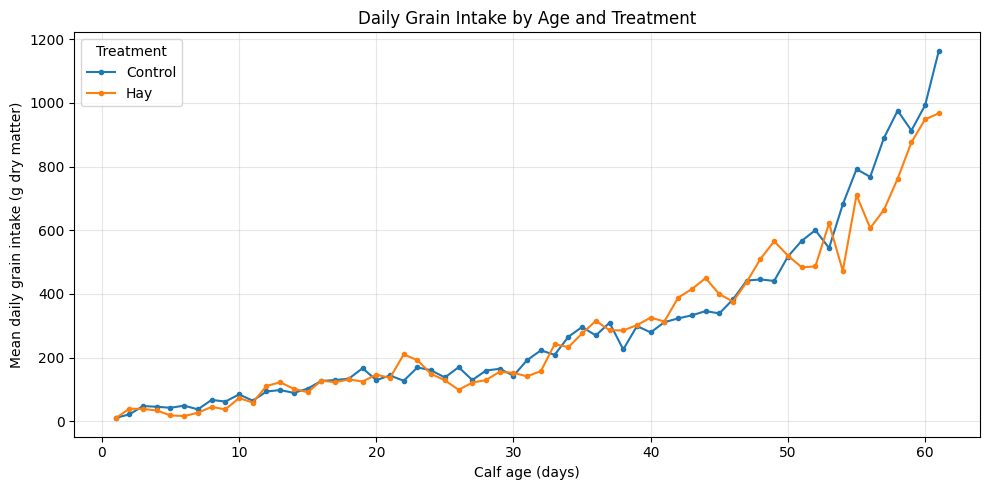

In [34]:
# Step 30: Plot mean daily grain intake by age and treatment

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for treatment in ["Control", "Hay"]:
    plot_data = grain_daily_summary[
        grain_daily_summary["Treatment"] == treatment
    ]

    plt.plot(
        plot_data["Age_days"],
        plot_data["mean_intake_g"],
        marker="o",
        markersize=3,
        label=treatment
    )

plt.xlabel("Calf age (days)")
plt.ylabel("Mean daily grain intake (g dry matter)")
plt.title("Daily Grain Intake by Age and Treatment")
plt.legend(title="Treatment")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Step 31 — Summarize daily hay intake by age

In [35]:
# Step 31: Summarize daily hay intake by calf age

hay_daily_summary = (
    hay.groupby("Age_days")["Hay_consumed_dried_g"]
    .agg(
        mean_intake_g="mean",
        calves_with_records="count"
    )
    .reset_index()
)

display(hay_daily_summary.head(20))

,Age_days,mean_intake_g,calves_with_records
0,1,2.334000,5
1,2,2.725000,4
2,3,3.582500,4
3,4,1.861667,6
4,5,2.077500,4
5,6,11.338000,5
6,7,2.592000,5
7,8,12.852222,9
8,9,9.232500,4
9,10,6.066000,5


Step 32 — Plot mean daily hay intake over time

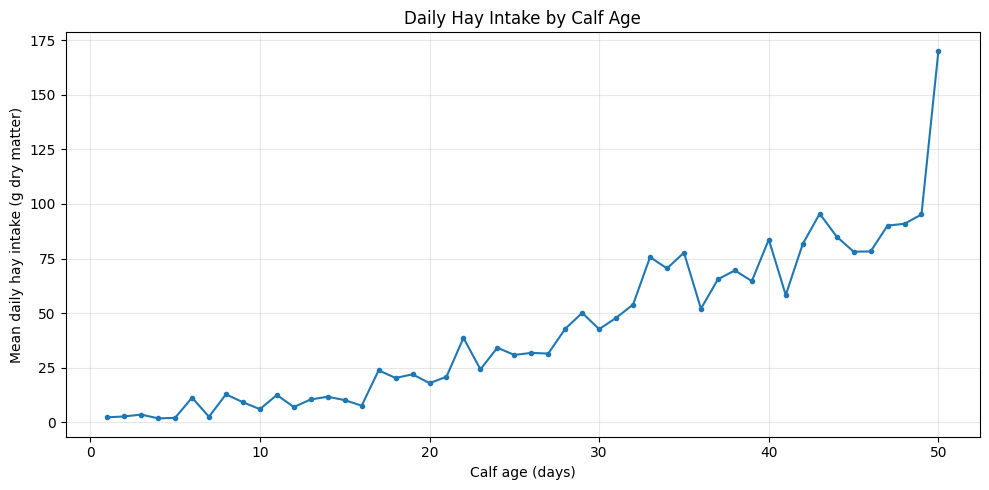

In [36]:
# Step 32: Plot mean daily hay intake by calf age

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    hay_daily_summary["Age_days"],
    hay_daily_summary["mean_intake_g"],
    marker="o",
    markersize=3
)

plt.xlabel("Calf age (days)")
plt.ylabel("Mean daily hay intake (g dry matter)")
plt.title("Daily Hay Intake by Calf Age")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Step 33 — Summarize daily TMR intake by age and treatment

In [37]:
# Step 33: Summarize daily TMR intake by age and treatment

tmr_daily_summary = (
    tmr.groupby(["Age_days", "Treatment"])["TMR_consumed_dried_g"]
    .agg(
        mean_intake_g="mean",
        calves_with_records="count"
    )
    .reset_index()
)

display(tmr_daily_summary)

,Age_days,Treatment,mean_intake_g,calves_with_records
0,49,Control,244.386667,3
1,49,Hay,207.156667,3
2,50,Control,197.280000,5
3,50,Hay,338.794286,7
4,51,Control,315.177778,9
5,51,Hay,418.471000,10
6,52,Control,234.203750,8
7,52,Hay,376.571000,10
8,53,Control,293.678571,7
9,53,Hay,546.212222,9


Step 34 — Plot daily TMR intake by age and treatment

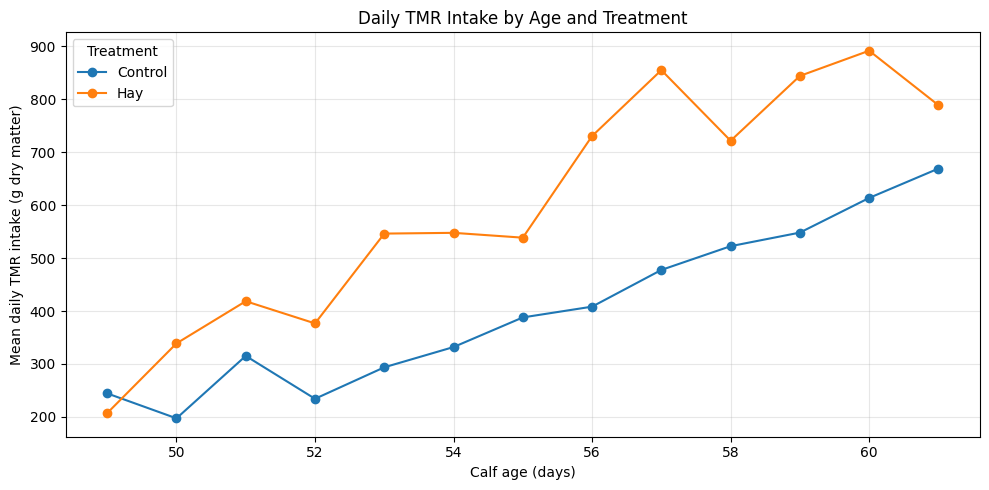

In [38]:
# Step 34: Plot mean daily TMR intake by age and treatment

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for treatment in ["Control", "Hay"]:
    plot_data = tmr_daily_summary[
        tmr_daily_summary["Treatment"] == treatment
    ]

    plt.plot(
        plot_data["Age_days"],
        plot_data["mean_intake_g"],
        marker="o",
        label=treatment
    )

plt.xlabel("Calf age (days)")
plt.ylabel("Mean daily TMR intake (g dry matter)")
plt.title("Daily TMR Intake by Age and Treatment")
plt.legend(title="Treatment")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Step 35 — Summarize feed intake across the study period

In [39]:
# Step 35: Summarize intake records by feed and treatment

intake_summary = pd.DataFrame([
    {
        "Feed": "Grain",
        "Treatment": treatment,
        "Records": group["Grain_consumed_dried_g"].count(),
        "Mean_intake_g": group["Grain_consumed_dried_g"].mean(),
        "SD_intake_g": group["Grain_consumed_dried_g"].std()
    }
    for treatment, group in grain.groupby("Treatment")
] + [
    {
        "Feed": "Hay",
        "Treatment": "Hay",
        "Records": hay["Hay_consumed_dried_g"].count(),
        "Mean_intake_g": hay["Hay_consumed_dried_g"].mean(),
        "SD_intake_g": hay["Hay_consumed_dried_g"].std()
    }
] + [
    {
        "Feed": "TMR",
        "Treatment": treatment,
        "Records": group["TMR_consumed_dried_g"].count(),
        "Mean_intake_g": group["TMR_consumed_dried_g"].mean(),
        "SD_intake_g": group["TMR_consumed_dried_g"].std()
    }
    for treatment, group in tmr.groupby("Treatment")
])

intake_summary[["Mean_intake_g", "SD_intake_g"]] = (
    intake_summary[["Mean_intake_g", "SD_intake_g"]].round(2)
)

display(intake_summary)

,Feed,Treatment,Records,Mean_intake_g,SD_intake_g
0,Grain,Control,615,291.96,327.75
1,Grain,Hay,596,276.81,287.24
2,Hay,Hay,415,47.16,51.39
3,TMR,Control,89,394.83,326.45
4,TMR,Hay,103,604.44,366.57


Step 36 — Examine the relationship between grain intake and body weight

In [40]:
# Step 36: Match grain intake records with calf weights

grain_weight_data = grain.merge(
    weights[["Calf", "Age_days", "Weight_kg"]],
    on=["Calf", "Age_days"],
    how="inner",
    validate="many_to_many"
)

print("Grain intake records:", len(grain))
print("Matched records:", len(grain_weight_data))
print("Unique calves matched:", grain_weight_data["Calf"].nunique())
print(
    "Missing grain intake values among matched records:",
    grain_weight_data["Grain_consumed_dried_g"].isna().sum()
)

display(grain_weight_data.head(10))

Grain intake records: 1321
Matched records: 184
Unique calves matched: 22
Missing grain intake values among matched records: 15


,Calf,Age_days,Date,Week,Treatment,Grain_consumed_dried_g,Weight_kg
0,2933,3,23-Jul-18,0,Hay,19.70,35.27
1,2933,10,30-Jul-18,1,Hay,101.81,41.20
2,2933,17,6-Aug-18,2,Hay,116.25,43.94
3,2933,24,13-Aug-18,3,Hay,74.20,48.46
4,2933,31,20-Aug-18,4,Hay,145.54,55.22
5,2933,38,27-Aug-18,5,Hay,593.35,64.87
6,2933,45,3-Sep-18,6,Hay,808.24,69.10
7,2933,52,10-Sep-18,7,Hay,524.71,80.61
8,2933,59,17-Sep-18,8,Hay,613.84,83.07
9,2934,8,30-Jul-18,1,Control,99.65,39.91


Step 37 — Assess the relationship between grain intake and body weight

Records analyzed: 169
Unique calves: 22
Pearson correlation (r): 0.728
p-value: 3.408e-29


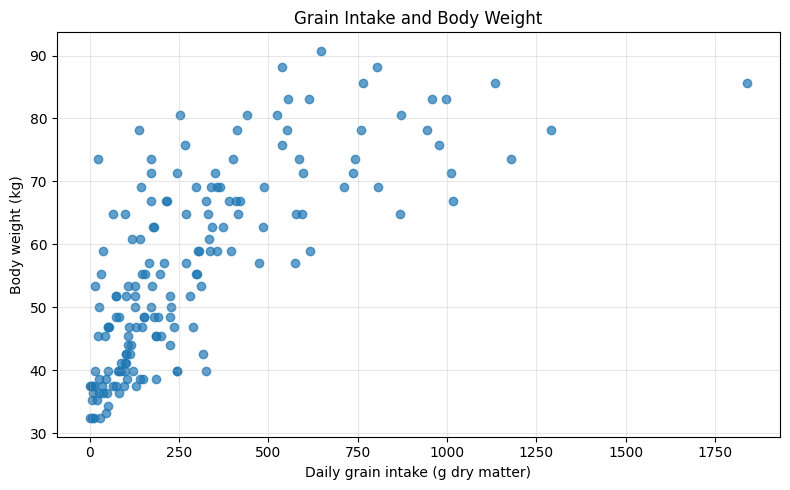

In [41]:
# Step 37: Grain intake and body weight relationship

from scipy.stats import pearsonr
import matplotlib.pyplot as plt

# Exclude records missing either measurement for this analysis
grain_weight_clean = grain_weight_data.dropna(
    subset=["Grain_consumed_dried_g", "Weight_kg"]
).copy()

# Calculate Pearson correlation
r, p_value = pearsonr(
    grain_weight_clean["Grain_consumed_dried_g"],
    grain_weight_clean["Weight_kg"]
)

print("Records analyzed:", len(grain_weight_clean))
print("Unique calves:", grain_weight_clean["Calf"].nunique())
print(f"Pearson correlation (r): {r:.3f}")
print(f"p-value: {p_value:.4g}")

# Plot the observed relationship
plt.figure(figsize=(8, 5))
plt.scatter(
    grain_weight_clean["Grain_consumed_dried_g"],
    grain_weight_clean["Weight_kg"],
    alpha=0.7
)

plt.xlabel("Daily grain intake (g dry matter)")
plt.ylabel("Body weight (kg)")
plt.title("Grain Intake and Body Weight")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Step 38 — Check the numerical correlation results

In [42]:
# Step 38: Display grain intake and body weight correlation results

print("Records analyzed:", len(grain_weight_clean))
print("Unique calves:", grain_weight_clean["Calf"].nunique())
print(f"Pearson correlation (r): {r:.3f}")
print(f"p-value: {p_value:.4g}")

Records analyzed: 169
Unique calves: 22
Pearson correlation (r): 0.728
p-value: 3.408e-29


Step 39 — Check whether age may explain part of the relationship

In [43]:
# Step 39: Examine age relationships in the matched grain dataset

from scipy.stats import pearsonr

age_grain_r, age_grain_p = pearsonr(
    grain_weight_clean["Age_days"],
    grain_weight_clean["Grain_consumed_dried_g"]
)

age_weight_r, age_weight_p = pearsonr(
    grain_weight_clean["Age_days"],
    grain_weight_clean["Weight_kg"]
)

print(f"Age vs grain intake — r: {age_grain_r:.3f}, p-value: {age_grain_p:.4g}")
print(f"Age vs body weight — r: {age_weight_r:.3f}, p-value: {age_weight_p:.4g}")

Age vs grain intake — r: 0.696, p-value: 8.795e-26
Age vs body weight — r: 0.955, p-value: 2.621e-90


Step 40 — Calculate the partial correlation controlling for age

In [44]:
# Step 40: Estimate grain intake–weight association controlling for age

import numpy as np
from scipy.stats import pearsonr

data = grain_weight_clean[
    ["Age_days", "Grain_consumed_dried_g", "Weight_kg"]
].copy()

# Remove the linear age trend from grain intake and body weight
grain_residuals = (
    data["Grain_consumed_dried_g"]
    - np.polyval(
        np.polyfit(data["Age_days"], data["Grain_consumed_dried_g"], 1),
        data["Age_days"]
    )
)

weight_residuals = (
    data["Weight_kg"]
    - np.polyval(
        np.polyfit(data["Age_days"], data["Weight_kg"], 1),
        data["Age_days"]
    )
)

# Correlate the residuals after accounting for age
partial_r, partial_p = pearsonr(grain_residuals, weight_residuals)

print(f"Records analyzed: {len(data)}")
print(f"Partial correlation controlling for age: {partial_r:.3f}")
print(f"Exploratory p-value: {partial_p:.4g}")

Records analyzed: 169
Partial correlation controlling for age: 0.299
Exploratory p-value: 7.922e-05


Step 41 — Compare the original and age-adjusted correlations

In [45]:
# Step 41: Compare original and age-adjusted correlations

correlation_comparison = pd.DataFrame({
    "Analysis": [
        "Grain intake vs body weight",
        "Partial correlation controlling for age"
    ],
    "Correlation": [
        r,
        partial_r
    ],
    "P_value": [
        p_value,
        partial_p
    ],
    "Records": [
        len(grain_weight_clean),
        len(data)
    ]
})

correlation_comparison["Correlation"] = (
    correlation_comparison["Correlation"].round(3)
)

correlation_comparison["P_value"] = (
    correlation_comparison["P_value"].apply(lambda x: f"{x:.4g}")
)

display(correlation_comparison)

,Analysis,Correlation,P_value,Records
0,Grain intake vs body weight,0.728,3.408e-29,169
1,Partial correlation controlling for age,0.299,7.922e-05,169


Step 42 — Next analysis

In [46]:
# Step 42: Match hay intake records with calf weights

hay_weight_data = hay.merge(
    weights[["Calf", "Age_days", "Weight_kg"]],
    on=["Calf", "Age_days"],
    how="inner",
    validate="many_to_many"
)

print("Hay intake records:", len(hay))
print("Matched records:", len(hay_weight_data))
print("Unique calves matched:", hay_weight_data["Calf"].nunique())
print(
    "Missing hay intake values among matched records:",
    hay_weight_data["Hay_consumed_dried_g"].isna().sum()
)

display(hay_weight_data.head(10))

Hay intake records: 539
Matched records: 76
Unique calves matched: 11
Missing hay intake values among matched records: 16


,Calf,Age_days,Date,Week,Treatment,Hay_consumed_dried_g,Weight_kg
0,2933,3,23-Jul-18,0,Hay,3.20,35.27
1,2933,10,30-Jul-18,1,Hay,NaN,41.20
2,2933,17,6-Aug-18,2,Hay,7.09,43.94
3,2933,24,13-Aug-18,3,Hay,88.00,48.46
4,2933,31,20-Aug-18,4,Hay,114.69,55.22
5,2933,38,27-Aug-18,5,Hay,50.91,64.87
6,2933,45,3-Sep-18,6,Hay,72.87,69.10
7,2935,8,30-Jul-18,1,Hay,NaN,36.35
8,2935,15,6-Aug-18,2,Hay,9.26,39.91
9,2935,22,13-Aug-18,3,Hay,NaN,45.40


Step 43 — Calculate the relationship between hay intake and body weight


In [47]:
# Step 43: Calculate correlation between hay intake and body weight

from scipy.stats import pearsonr

hay_weight_clean = hay_weight_data.dropna(
    subset=["Hay_consumed_dried_g", "Weight_kg"]
).copy()

hay_r, hay_p_value = pearsonr(
    hay_weight_clean["Hay_consumed_dried_g"],
    hay_weight_clean["Weight_kg"]
)

print("Records analyzed:", len(hay_weight_clean))
print("Unique calves:", hay_weight_clean["Calf"].nunique())
print(f"Pearson correlation (r): {hay_r:.3f}")
print(f"p-value: {hay_p_value:.4g}")

Records analyzed: 60
Unique calves: 11
Pearson correlation (r): 0.683
p-value: 1.801e-09


Step 44 — Check whether age may explain part of the hay relationship

In [48]:
# Step 44: Examine age relationships in the matched hay dataset

from scipy.stats import pearsonr

age_hay_r, age_hay_p = pearsonr(
    hay_weight_clean["Age_days"],
    hay_weight_clean["Hay_consumed_dried_g"]
)

age_weight_hay_r, age_weight_hay_p = pearsonr(
    hay_weight_clean["Age_days"],
    hay_weight_clean["Weight_kg"]
)

print(
    f"Age vs hay intake — r: {age_hay_r:.3f}, "
    f"p-value: {age_hay_p:.4g}"
)

print(
    f"Age vs body weight — r: {age_weight_hay_r:.3f}, "
    f"p-value: {age_weight_hay_p:.4g}"
)

Age vs hay intake — r: 0.635, p-value: 5.132e-08
Age vs body weight — r: 0.943, p-value: 2.333e-29


Step 45 — Calculate the hay intake–weight association controlling for age


In [49]:
# Step 45: Estimate hay intake–weight association controlling for age

import numpy as np
from scipy.stats import pearsonr

data_hay = hay_weight_clean[
    ["Age_days", "Hay_consumed_dried_g", "Weight_kg"]
].copy()

# Remove the linear age trend from hay intake
hay_residuals = (
    data_hay["Hay_consumed_dried_g"]
    - np.polyval(
        np.polyfit(
            data_hay["Age_days"],
            data_hay["Hay_consumed_dried_g"],
            1
        ),
        data_hay["Age_days"]
    )
)

# Remove the linear age trend from body weight
weight_residuals_hay = (
    data_hay["Weight_kg"]
    - np.polyval(
        np.polyfit(
            data_hay["Age_days"],
            data_hay["Weight_kg"],
            1
        ),
        data_hay["Age_days"]
    )
)

# Correlate the residuals
hay_partial_r, hay_partial_p = pearsonr(
    hay_residuals,
    weight_residuals_hay
)

print("Records analyzed:", len(data_hay))
print(f"Partial correlation controlling for age: {hay_partial_r:.3f}")
print(f"Exploratory p-value: {hay_partial_p:.4g}")

Records analyzed: 60
Partial correlation controlling for age: 0.329
Exploratory p-value: 0.01024


Step 45 — Interpretation of the age-adjusted hay relationship

In [50]:
# Step 46: Compare original and age-adjusted hay correlations

hay_correlation_comparison = pd.DataFrame({
    "Analysis": [
        "Hay intake vs body weight",
        "Partial correlation controlling for age"
    ],
    "Correlation": [
        hay_r,
        hay_partial_r
    ],
    "P_value": [
        hay_p_value,
        hay_partial_p
    ],
    "Records": [
        len(hay_weight_clean),
        len(data_hay)
    ]
})

hay_correlation_comparison["Correlation"] = (
    hay_correlation_comparison["Correlation"].round(3)
)

hay_correlation_comparison["P_value"] = (
    hay_correlation_comparison["P_value"].apply(
        lambda value: f"{value:.4g}"
    )
)

display(hay_correlation_comparison)

,Analysis,Correlation,P_value,Records
0,Hay intake vs body weight,0.683,1.801e-09,60
1,Partial correlation controlling for age,0.329,0.01024,60


Step 47 — Match TMR intake records with calf weights

In [51]:
# Step 47: Match TMR intake records with calf weights

tmr_weight_data = tmr.merge(
    weights[["Calf", "Age_days", "Weight_kg"]],
    on=["Calf", "Age_days"],
    how="inner",
    validate="many_to_many"
)

print("TMR intake records:", len(tmr))
print("Matched records:", len(tmr_weight_data))
print("Unique calves matched:", tmr_weight_data["Calf"].nunique())
print(
    "Missing TMR intake values among matched records:",
    tmr_weight_data["TMR_consumed_dried_g"].isna().sum()
)

display(tmr_weight_data.head(10))

TMR intake records: 241
Matched records: 33
Unique calves matched: 22
Missing TMR intake values among matched records: 2


,Calf,Age_days,Date,Week,Treatment,TMR_consumed_dried_g,Weight_kg
0,2933,52,10-Sep-18,7,Hay,235.57,80.61
1,2933,59,17-Sep-18,8,Hay,1732.94,83.07
2,2934,50,10-Sep-18,7,Control,564.58,73.54
3,2934,57,17-Sep-18,8,Control,1291.50,78.20
4,2935,50,10-Sep-18,7,Hay,369.97,69.10
5,2935,57,17-Sep-18,8,Hay,930.94,71.29
6,2936,57,17-Sep-18,8,Control,NaN,88.15
7,2937,57,17-Sep-18,8,Hay,903.83,90.77
8,2938,57,17-Sep-18,8,Control,248.08,78.20
9,2939,57,17-Sep-18,8,Hay,1130.17,83.07


Step 48 — Calculate the TMR intake–body weight correlation

In [52]:
# Step 48: Calculate correlation between TMR intake and body weight

from scipy.stats import pearsonr

tmr_weight_clean = tmr_weight_data.dropna(
    subset=["TMR_consumed_dried_g", "Weight_kg"]
).copy()

tmr_r, tmr_p_value = pearsonr(
    tmr_weight_clean["TMR_consumed_dried_g"],
    tmr_weight_clean["Weight_kg"]
)

print("Records analyzed:", len(tmr_weight_clean))
print("Unique calves:", tmr_weight_clean["Calf"].nunique())
print(f"Pearson correlation (r): {tmr_r:.3f}")
print(f"p-value: {tmr_p_value:.4g}")

Records analyzed: 31
Unique calves: 20
Pearson correlation (r): 0.188
p-value: 0.3099


Step 49 — Check whether age is related to TMR intake and body weight

In [53]:
# Step 49: Examine age relationships in the matched TMR dataset

from scipy.stats import pearsonr

age_tmr_r, age_tmr_p = pearsonr(
    tmr_weight_clean["Age_days"],
    tmr_weight_clean["TMR_consumed_dried_g"]
)

age_weight_tmr_r, age_weight_tmr_p = pearsonr(
    tmr_weight_clean["Age_days"],
    tmr_weight_clean["Weight_kg"]
)

print(
    f"Age vs TMR intake — r: {age_tmr_r:.3f}, "
    f"p-value: {age_tmr_p:.4g}"
)

print(
    f"Age vs body weight — r: {age_weight_tmr_r:.3f}, "
    f"p-value: {age_weight_tmr_p:.4g}"
)

Age vs TMR intake — r: 0.511, p-value: 0.003334
Age vs body weight — r: 0.483, p-value: 0.005869


Step 50 — Calculate the TMR intake–weight association controlling for age

In [54]:
# Step 50: Estimate TMR intake–weight association controlling for age

import numpy as np
from scipy.stats import pearsonr

data_tmr = tmr_weight_clean[
    ["Age_days", "TMR_consumed_dried_g", "Weight_kg"]
].copy()

# Remove the linear age trend from TMR intake
tmr_residuals = (
    data_tmr["TMR_consumed_dried_g"]
    - np.polyval(
        np.polyfit(
            data_tmr["Age_days"],
            data_tmr["TMR_consumed_dried_g"],
            1
        ),
        data_tmr["Age_days"]
    )
)

# Remove the linear age trend from body weight
weight_residuals_tmr = (
    data_tmr["Weight_kg"]
    - np.polyval(
        np.polyfit(
            data_tmr["Age_days"],
            data_tmr["Weight_kg"],
            1
        ),
        data_tmr["Age_days"]
    )
)

# Correlate the residuals
tmr_partial_r, tmr_partial_p = pearsonr(
    tmr_residuals,
    weight_residuals_tmr
)

print("Records analyzed:", len(data_tmr))
print(f"Partial correlation controlling for age: {tmr_partial_r:.3f}")
print(f"Exploratory p-value: {tmr_partial_p:.4g}")

Records analyzed: 31
Partial correlation controlling for age: -0.078
Exploratory p-value: 0.6784


Step 51 — Compare the results for all three feeds

In [55]:
# Step 51: Compare feed intake–weight correlations

feed_correlation_summary = pd.DataFrame([
    {
        "Feed": "Grain",
        "Records": len(grain_weight_clean),
        "Unique_calves": grain_weight_clean["Calf"].nunique(),
        "Original_r": r,
        "Original_p": p_value,
        "Age_adjusted_r": partial_r,
        "Age_adjusted_p": partial_p
    },
    {
        "Feed": "Hay",
        "Records": len(hay_weight_clean),
        "Unique_calves": hay_weight_clean["Calf"].nunique(),
        "Original_r": hay_r,
        "Original_p": hay_p_value,
        "Age_adjusted_r": hay_partial_r,
        "Age_adjusted_p": hay_partial_p
    },
    {
        "Feed": "TMR",
        "Records": len(tmr_weight_clean),
        "Unique_calves": tmr_weight_clean["Calf"].nunique(),
        "Original_r": tmr_r,
        "Original_p": tmr_p_value,
        "Age_adjusted_r": tmr_partial_r,
        "Age_adjusted_p": tmr_partial_p
    }
])

feed_correlation_summary[
    ["Original_r", "Age_adjusted_r"]
] = feed_correlation_summary[
    ["Original_r", "Age_adjusted_r"]
].round(3)

feed_correlation_summary[
    ["Original_p", "Age_adjusted_p"]
] = feed_correlation_summary[
    ["Original_p", "Age_adjusted_p"]
].apply(lambda column: column.map(lambda value: f"{value:.4g}"))

display(feed_correlation_summary)

,Feed,Records,Unique_calves,Original_r,Original_p,Age_adjusted_r,Age_adjusted_p
0,Grain,169,22,0.728,3.408e-29,0.299,7.922e-05
1,Hay,60,11,0.683,1.801e-09,0.329,0.01024
2,TMR,31,20,0.188,0.3099,-0.078,0.6784


Step 52 — Examine the matched sample sizes and age ranges

In [56]:
# Step 52: Summarize age coverage in each matched feed-weight dataset

matched_datasets = {
    "Grain": grain_weight_clean,
    "Hay": hay_weight_clean,
    "TMR": tmr_weight_clean
}

age_coverage = []

for feed_name, data in matched_datasets.items():
    age_coverage.append({
        "Feed": feed_name,
        "Complete_records": len(data),
        "Unique_calves": data["Calf"].nunique(),
        "Minimum_age_days": data["Age_days"].min(),
        "Maximum_age_days": data["Age_days"].max(),
        "Mean_age_days": round(data["Age_days"].mean(), 1)
    })

age_coverage_df = pd.DataFrame(age_coverage)
display(age_coverage_df)

,Feed,Complete_records,Unique_calves,Minimum_age_days,Maximum_age_days,Mean_age_days
0,Grain,169,22,1,61,32.1
1,Hay,60,11,1,50,28.0
2,TMR,31,20,49,61,54.7


Step 53 — Check whether missing feed-intake values vary by age

In [57]:
# Step 53: Summarize missing intake values by age

feed_datasets = {
    "Grain": (grain, "Grain_consumed_dried_g"),
    "Hay": (hay, "Hay_consumed_dried_g"),
    "TMR": (tmr, "TMR_consumed_dried_g")
}

missing_by_age = []

for feed_name, (data, intake_column) in feed_datasets.items():
    age_summary = (
        data.groupby("Age_days")
        .agg(
            Total_records=(intake_column, "size"),
            Missing_intake=(intake_column, lambda values: values.isna().sum())
        )
        .reset_index()
    )

    age_summary["Feed"] = feed_name
    age_summary["Missing_percentage"] = (
        age_summary["Missing_intake"] / age_summary["Total_records"] * 100
    ).round(1)

    missing_by_age.append(age_summary)

missing_by_age_df = pd.concat(missing_by_age, ignore_index=True)

display(
    missing_by_age_df[
        missing_by_age_df["Missing_intake"] > 0
    ].sort_values(["Feed", "Age_days"])
)

,Age_days,Total_records,Missing_intake,Feed,Missing_percentage
0,1,22,6,Grain,27.3
1,2,22,7,Grain,31.8
2,3,22,2,Grain,9.1
3,4,22,6,Grain,27.3
4,5,22,4,Grain,18.2
...,...,...,...,...,...
119,57,22,3,TMR,13.6
120,58,22,4,TMR,18.2
121,59,21,6,TMR,28.6
122,60,16,5,TMR,31.2


Step 54 — Summarize missingness for each feed

In [58]:
# Step 54: Calculate overall missing intake percentages

missing_summary = []

for feed_name, (data, intake_column) in feed_datasets.items():
    total_records = len(data)
    missing_records = data[intake_column].isna().sum()
    observed_records = data[intake_column].notna().sum()

    missing_summary.append({
        "Feed": feed_name,
        "Total_records": total_records,
        "Observed_intake": observed_records,
        "Missing_intake": missing_records,
        "Missing_percentage": round(
            missing_records / total_records * 100, 2
        )
    })

missing_summary_df = pd.DataFrame(missing_summary)
display(missing_summary_df)

,Feed,Total_records,Observed_intake,Missing_intake,Missing_percentage
0,Grain,1321,1211,110,8.33
1,Hay,539,415,124,23.01
2,TMR,241,192,49,20.33


Step 55 — Compare observed intake by treatment during the weaning period

In [59]:
# Step 55: Summarize TMR data completeness by treatment

tmr_treatment_summary = (
    tmr.groupby("Treatment")
    .agg(
        Total_records=("TMR_consumed_dried_g", "size"),
        Observed_intake=("TMR_consumed_dried_g", "count"),
        Missing_intake=("TMR_consumed_dried_g", lambda x: x.isna().sum()),
        Unique_calves=("Calf", "nunique"),
        Mean_observed_intake_g=("TMR_consumed_dried_g", "mean")
    )
    .reset_index()
)

tmr_treatment_summary["Missing_percentage"] = (
    tmr_treatment_summary["Missing_intake"]
    / tmr_treatment_summary["Total_records"] * 100
).round(2)

tmr_treatment_summary["Mean_observed_intake_g"] = (
    tmr_treatment_summary["Mean_observed_intake_g"].round(2)
)

display(tmr_treatment_summary)

,Treatment,Total_records,Observed_intake,Missing_intake,Unique_calves,Mean_observed_intake_g,Missing_percentage
0,Control,121,89,32,11,394.83,26.45
1,Hay,120,103,17,11,604.44,14.17


Step 56 — Compare observed TMR intake across the two treatments by age

In [60]:
# Step 56: Compare observed TMR intake by age and treatment

tmr_age_comparison = (
    tmr.groupby(["Age_days", "Treatment"])
    .agg(
        Mean_intake_g=("TMR_consumed_dried_g", "mean"),
        Observed_records=("TMR_consumed_dried_g", "count")
    )
    .reset_index()
)

tmr_age_comparison["Mean_intake_g"] = (
    tmr_age_comparison["Mean_intake_g"].round(2)
)

tmr_age_pivot = tmr_age_comparison.pivot(
    index="Age_days",
    columns="Treatment",
    values="Mean_intake_g"
).reset_index()

tmr_count_pivot = tmr_age_comparison.pivot(
    index="Age_days",
    columns="Treatment",
    values="Observed_records"
).reset_index()

tmr_age_comparison_table = tmr_age_pivot.merge(
    tmr_count_pivot,
    on="Age_days",
    suffixes=("_mean_g", "_n")
)

display(tmr_age_comparison_table)

Treatment,Age_days,Control_mean_g,Hay_mean_g,Control_n,Hay_n
0,49,244.39,207.16,3,3
1,50,197.28,338.79,5,7
2,51,315.18,418.47,9,10
3,52,234.20,376.57,8,10
4,53,293.68,546.21,7,9
5,54,331.92,547.63,8,9
6,55,387.87,538.50,9,10
7,56,408.22,730.44,8,9
8,57,477.57,854.92,9,10
9,58,522.44,721.54,9,9


Step 57 — Calculate the daily difference in mean TMR intake

In [61]:
# Step 57: Calculate daily differences in observed mean TMR intake

tmr_daily_difference = tmr_age_comparison_table[
    ["Age_days", "Control_mean_g", "Hay_mean_g", "Control_n", "Hay_n"]
].copy()

tmr_daily_difference["Hay_minus_Control_g"] = (
    tmr_daily_difference["Hay_mean_g"]
    - tmr_daily_difference["Control_mean_g"]
).round(2)

display(tmr_daily_difference)

Treatment,Age_days,Control_mean_g,Hay_mean_g,Control_n,Hay_n,Hay_minus_Control_g
0,49,244.39,207.16,3,3,-37.23
1,50,197.28,338.79,5,7,141.51
2,51,315.18,418.47,9,10,103.29
3,52,234.20,376.57,8,10,142.37
4,53,293.68,546.21,7,9,252.53
5,54,331.92,547.63,8,9,215.71
6,55,387.87,538.50,9,10,150.63
7,56,408.22,730.44,8,9,322.22
8,57,477.57,854.92,9,10,377.35
9,58,522.44,721.54,9,9,199.10


Step 58 — Summarize the daily differences

In [62]:
# Step 58: Summarize daily TMR intake differences

difference_summary = pd.DataFrame({
    "Statistic": [
        "Number of days",
        "Mean daily difference (g)",
        "Median daily difference (g)",
        "Minimum daily difference (g)",
        "Maximum daily difference (g)",
        "Days Hay mean exceeded Control",
        "Days Control mean exceeded Hay"
    ],
    "Value": [
        len(tmr_daily_difference),
        round(tmr_daily_difference["Hay_minus_Control_g"].mean(), 2),
        round(tmr_daily_difference["Hay_minus_Control_g"].median(), 2),
        round(tmr_daily_difference["Hay_minus_Control_g"].min(), 2),
        round(tmr_daily_difference["Hay_minus_Control_g"].max(), 2),
        int((tmr_daily_difference["Hay_minus_Control_g"] > 0).sum()),
        int((tmr_daily_difference["Hay_minus_Control_g"] < 0).sum())
    ]
})

display(difference_summary)

,Statistic,Value
0,Number of days,13.00
1,Mean daily difference (g),197.01
2,Median daily difference (g),199.10
3,Minimum daily difference (g),-37.23
4,Maximum daily difference (g),377.35
5,Days Hay mean exceeded Control,12.00
6,Days Control mean exceeded Hay,1.00


Step 59 — Calculate the percentage difference in daily mean TMR intake

In [63]:
# Step 59: Calculate daily percentage differences relative to Control

tmr_daily_difference["Hay_vs_Control_percent"] = (
    (
        tmr_daily_difference["Hay_mean_g"]
        - tmr_daily_difference["Control_mean_g"]
    )
    / tmr_daily_difference["Control_mean_g"]
    * 100
).round(2)

display(
    tmr_daily_difference[
        [
            "Age_days",
            "Control_mean_g",
            "Hay_mean_g",
            "Hay_minus_Control_g",
            "Hay_vs_Control_percent"
        ]
    ]
)

Treatment,Age_days,Control_mean_g,Hay_mean_g,Hay_minus_Control_g,Hay_vs_Control_percent
0,49,244.39,207.16,-37.23,-15.23
1,50,197.28,338.79,141.51,71.73
2,51,315.18,418.47,103.29,32.77
3,52,234.20,376.57,142.37,60.79
4,53,293.68,546.21,252.53,85.99
5,54,331.92,547.63,215.71,64.99
6,55,387.87,538.50,150.63,38.84
7,56,408.22,730.44,322.22,78.93
8,57,477.57,854.92,377.35,79.01
9,58,522.44,721.54,199.10,38.11


Finalize the analysis

In [64]:
# Step 1: List files in the current Colab working directory

import os

for filename in sorted(os.listdir(".")):
    print(filename)

.config
JDS.2021-21439_1-0_behavioral_data.csv
JDS.2021-21439_Grain_intake_data.csv
JDS.2021-21439_Hay_intake_data.csv
JDS.2021-21439_README.pdf
JDS.2021-21439_TMR_intake_data.csv
JDS.2021-21439_Water_intake_data.csv
JDS.2021-21439_Weekly_calf_weights_and_ADG.xlsx
sample_data


Check whether the analysis notebook is saved

In [65]:
# Step 2: Check for saved notebook and analysis output files

import os

for filename in sorted(os.listdir(".")):
    if filename.endswith((".ipynb", ".png", ".csv", ".xlsx")):
        print(filename)

JDS.2021-21439_1-0_behavioral_data.csv
JDS.2021-21439_Grain_intake_data.csv
JDS.2021-21439_Hay_intake_data.csv
JDS.2021-21439_TMR_intake_data.csv
JDS.2021-21439_Water_intake_data.csv
JDS.2021-21439_Weekly_calf_weights_and_ADG.xlsx


## Key Findings and Limitations

### Key Findings

- **Calf growth:** Mean body weight increased across the study period in both the Control and Hay groups.
- **Observed weight gain:** Mean observed weight change was approximately 41.4 kg for Control calves and 41.8 kg for Hay calves.
- **Feed intake:** Mean grain intake generally increased with age. Hay intake also tended to increase during its measurement period, while TMR intake generally increased during weaning.
- **TMR comparison:** The Hay group had a higher observed mean TMR intake on 12 of the 13 recorded days. These are descriptive comparisons, not proof of a treatment effect.
- **Intake and body weight:** Grain and hay intake had positive original correlations with body weight, but these relationships weakened after adjusting for age. The age-adjusted TMR correlation was close to zero.
- **Data completeness:** Missing intake values accounted for 8.33% of grain records, 23.01% of hay records, and 20.33% of TMR records.

### Limitations

- The study included 22 calves, with 11 calves in each treatment group.
- Measurements were repeated over time for the same calves and should not be treated as independent observations.
- Feed datasets covered different age ranges and had different levels of missingness.
- The exploratory correlations do not account fully for repeated measurements within calves.
- Descriptive differences do not establish that hay provision caused differences in intake or growth.
- The endpoint-based average daily gain calculated in this project is distinct from the study's supplied ADG measure.

### Conclusion

This project demonstrates a reproducible workflow for exploring dairy calf growth and feed intake using Python and pandas. It includes data-quality checks, descriptive statistics, visualizations, and exploratory correlation analysis. The findings describe patterns in the available data; stronger conclusions about treatment effects would require an analysis that accounts for age, repeated measurements, and the study design.

In [66]:
# Step 4: Load the four research datasets

import pandas as pd

grain = pd.read_csv("JDS.2021-21439_Grain_intake_data.csv")
hay = pd.read_csv("JDS.2021-21439_Hay_intake_data.csv")
tmr = pd.read_csv("JDS.2021-21439_TMR_intake_data.csv")

weights = pd.read_excel(
    "JDS.2021-21439_Weekly_calf_weights_and_ADG.xlsx"
)

print("All four research datasets loaded successfully.")

All four research datasets loaded successfully.


In [67]:
# Step 5: Verify the four research datasets

datasets = {
    "Grain intake": grain,
    "Hay intake": hay,
    "TMR intake": tmr,
    "Weekly calf weights": weights
}

for name, data in datasets.items():
    print(f"{name}: {data.shape[0]} rows × {data.shape[1]} columns")

Grain intake: 1321 rows × 6 columns
Hay intake: 539 rows × 6 columns
TMR intake: 241 rows × 6 columns
Weekly calf weights: 206 rows × 6 columns
